# 1. Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 2. Gathering Data

In [4]:
# Load the dataset
df = pd.read_csv('dataset.csv')
df.head()

,Tahun,Bulan,Jenis,room,bed,room_yesterday,room_in,room_out,wna_yesterday,wni_yesterday,...,RLMTA,MTNUS,TNUS,RLMTNUS,MTGAB,TGAB,RLMTGAB,TPTT,Bulan_Num,Tanggal
0,2022,Januari,Bintang,2325,3968,1647,1624,1647,0,3466,...,#DIV/0!,3434,3262,1.05,3434,3262,1.05,86.54,1,2022-01-01
1,2022,Januari,Bintang,30235,43472,17331,10575,10504,35,27557,...,2.06,27674,18258,1.52,27711,18276,1.52,63.74,1,2022-01-01
2,2022,Januari,Bintang,37318,53478,17891,14128,14127,8,28700,...,1.00,28631,22837,1.25,28639,22845,1.25,53.55,1,2022-01-01
3,2022,Januari,Bintang,5208,7316,2827,2391,2478,0,5118,...,#DIV/0!,4957,4280,1.16,4957,4280,1.16,67.76,1,2022-01-01
4,2022,Januari,Bintang,1054,1891,960,768,753,0,2420,...,#DIV/0!,2470,1536,1.61,2470,1536,1.61,130.62,1,2022-01-01


# 3. Assesing Data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2476 entries, 0 to 2475
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Tahun                      2476 non-null   int64  
 1   Bulan                      2476 non-null   object 
 2   Jenis                      2476 non-null   object 
 3   room                       2476 non-null   int64  
 4   bed                        2476 non-null   int64  
 5   room_yesterday             2476 non-null   int64  
 6   room_in                    2476 non-null   int64  
 7   room_out                   2476 non-null   int64  
 8   wna_yesterday              2476 non-null   int64  
 9   wni_yesterday              2476 non-null   int64  
 10  wna_in/jml_tamu_asing      2476 non-null   int64  
 11  wni_in/jml_tamu_nusantara  2476 non-null   int64  
 12  wna_out                    2476 non-null   int64  
 13  wni_out                    2476 non-null   int64

In [6]:
# Cek jumlah duplikat
# Harus dicek manual di Spreadsheetnya
duplikat = df.duplicated()
print(f"Jumlah baris duplikat: {duplikat.sum()}")

# Tampilkan contoh duplikat
df[duplikat]

Jumlah baris duplikat: 11


,Tahun,Bulan,Jenis,room,bed,room_yesterday,room_in,room_out,wna_yesterday,wni_yesterday,...,RLMTA,MTNUS,TNUS,RLMTNUS,MTGAB,TGAB,RLMTGAB,TPTT,Bulan_Num,Tanggal
194,2023,Januari,Non Bintang,355,711,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,1,2023-01-01
198,2023,Januari,Non Bintang,355,711,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,1,2023-01-01
333,2023,Februari,Non Bintang,336,672,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,2,2023-02-01
747,2023,April,Non Bintang,396,792,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,4,2023-04-01
754,2023,April,Non Bintang,1397,2793,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,4,2023-04-01
1320,2023,Juli,Non Bintang,446,893,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,7,2023-07-01
1739,2023,September,Non Bintang,396,792,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,9,2023-09-01
1817,2023,Oktober,Non Bintang,1685,1685,1074,1074,1074,0,2179,...,#DIV/0!,2179,2179,1.00,2179,2179,1.00,129.32,10,2023-10-01
1955,2023,Oktober,Non Bintang,409,818,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,10,2023-10-01
2077,2023,November,Non Bintang,396,792,0,0,0,0,0,...,#DIV/0!,0,0,#DIV/0!,0,0,#DIV/0!,0.00,11,2023-11-01


In [7]:
#Memastikan Adanya Missing Value
df.isna().sum()

,0
Tahun,0
Bulan,0
Jenis,0
room,0
bed,0
room_yesterday,0
room_in,0
room_out,0
wna_yesterday,0
wni_yesterday,0


# 4. Cleaning Data dan EDA

## Menggabungkan TPTT Gabungan (Tanggal dan TPTT Historis)

In [8]:
# --- 1. Muat Kedua Data ---

# Data Historis
df_historical_raw = pd.read_csv('dataset.csv')

# --- 2. Konversi Kolom Tanggal ke Datetime ---
df_historical_raw['Tanggal'] = pd.to_datetime(df_historical_raw['Tanggal'])

# --- 3. Pilih Kolom Relevan & Beri Nama Jelas ---

# Untuk data historis, agregasi TPTT per bulan/tanggal
# Karena data historis Anda tampaknya memiliki beberapa entri TPTT per Tanggal, kita akan ambil rata-ratanya
tptt_ts_historical = df_historical_raw.dropna(subset=['TPTT']).groupby('Tanggal')['TPTT'].mean()
df_historical_clean = pd.DataFrame({
    'Tanggal': tptt_ts_historical.index,
    'TPTT Historis': tptt_ts_historical.values
})

# Pastikan kedua DataFrame menggunakan 'Tanggal' sebagai indeks untuk penggabungan yang mudah
df_historical_clean = df_historical_clean.set_index('Tanggal')

# Menggunakan outer join agar semua tanggal (historis) disertakan
# dan nilai yang tidak ada diisi dengan NaN
combined_df = pd.concat([df_historical_clean], axis=1)
# Urutkan Data dan Reset Indeks (Opsional) ---
combined_df = combined_df.sort_index().reset_index()
combined_df = combined_df.rename(columns={'index': 'Tanggal'}) # Ganti nama kolom indeks kembali ke Tanggal


# --- 6. Simpan Data Gabungan ke CSV Baru ---
output_csv_filename = 'TPTT_Tanggal_Historis.csv'
combined_df.to_csv(output_csv_filename, index=False)

print(f"Data gabungan berhasil dibuat dan disimpan sebagai '{output_csv_filename}'.")
print("\nLima baris pertama data gabungan:")
print(combined_df.head())
print("\nLima baris terakhir data gabungan:")
print(combined_df.tail())

Data gabungan berhasil dibuat dan disimpan sebagai 'TPTT_Tanggal_Historis.csv'.

Lima baris pertama data gabungan:
     Tanggal  TPTT Historis
0 2022-01-01      61.220000
1 2022-02-01      58.224444
2 2022-03-01      59.410000
3 2022-04-01      37.547778
4 2022-05-01      70.066667

Lima baris terakhir data gabungan:
      Tanggal  TPTT Historis
36 2025-01-01         34.205
37 2025-02-01         31.895
38 2025-03-01         23.105
39 2025-04-01         37.445
40 2025-05-01         35.360


# 5. TPTT dan Prediksi Metode Fuzzy Time Series (2022-2025)

Mean Absolute Error (MAE): 0.01
Root Mean Squared Error (RMSE): 0.01
Mean Absolute Percentage Error (MAPE): 0.02%
Mean Error (ME): 0.00
Plot saved to tptt_prediction_fts.png
Hasil prediksi telah disimpan ke prediksi_tptt_fts.csv


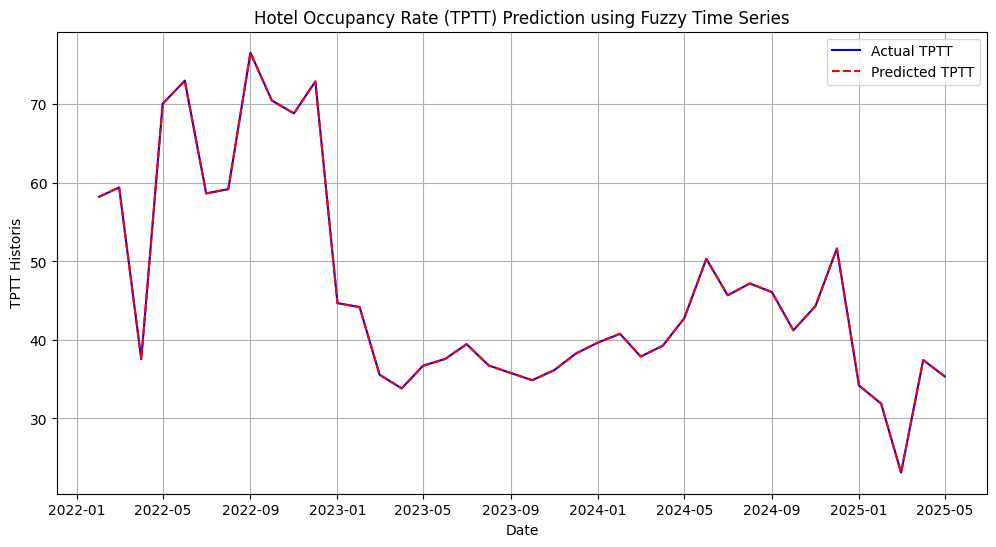

In [9]:
# Load the dataset
df = pd.read_csv('TPTT_Tanggal_Historis.csv')

# Convert 'Tanggal' to datetime and set as index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Select the 'TPK Historis' column for prediction
data = df['TPTT Historis'].values

# Step 1: Define the Universe of Discourse (U)
# Find min and max of the data
D_min = data.min()
D_max = data.max()

# Define an extended range for the universe of discourse
# Adding a small buffer for D1 and D2 based on the data range
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

# Step 2: Partition the Universe of Discourse into Intervals
num_intervals = 1400 # Number of intervals, can be tuned
interval_length = (U_end - U_start) / num_intervals
intervals = []
for i in range(num_intervals):
    start = U_start + i * interval_length
    end = start + interval_length
    intervals.append((start, end))

# Step 3: Define Fuzzy Sets (A1, A2, ..., An)
# Using midpoints of intervals as representative values for fuzzy sets
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify the Historical Data
def fuzzify(value, intervals):
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i # Return the index of the interval/fuzzy set
    # Handle edge cases for values slightly outside the defined intervals
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return num_intervals - 1
    return None # Should not happen if universe of discourse is well-defined

fuzzified_data = [fuzzify(val, intervals) for val in data]

# Step 5 & 6: Establish Fuzzy Logical Relationships (FLRs) and Group FLRs (FLRGs)
flrs = {} # Dictionary to store FLRs: {current_state: [next_states]}
for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]
    next_state = fuzzified_data[i+1]
    if current_state not in flrs:
        flrs[current_state] = []
    flrs[current_state].append(next_state)

# For Chen's method, FLRGs are formed by unique next states for each current state
flrgs = {}
for current_state, next_states in flrs.items():
    flrgs[current_state] = sorted(list(set(next_states))) # Unique and sorted next states

# Step 7: Forecast (Defuzzification)
# For prediction, we use the FLRGs. If multiple next states, take average of midpoints.
# If no relation, use the previous value's fuzzy set's midpoint.

predictions = []
# Start predictions from the first element where an FLR can be formed
# The first prediction will be for data[1] using data[0]
for i in range(len(fuzzified_data) - 1):
    current_fuzzy_state = fuzzified_data[i]
    if current_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_fuzzy_state]
        # Calculate the average of the midpoints of the possible next states
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            predictions.append(np.mean(predicted_midpoints))
        else:
            # Fallback if for some reason there are no next states (shouldn't happen with this logic)
            predictions.append(fuzzy_sets[current_fuzzy_state])
    else:
        # If no relationship found, a simple approach is to use the current fuzzy set's midpoint
        predictions.append(fuzzy_sets[current_fuzzy_state])


# The length of predictions will be len(data) - 1. We need to align it with original data.
# For evaluation, we compare predictions (from index 0) with actual values (from index 1).
actual_values = data[1:]
predicted_values = np.array(predictions)

# Ensure the lengths match for evaluation
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]

# Calculate evaluation metrics
mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))

# MAPE calculation - handle division by zero for actual_values_eval that are 0
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / actual_values_eval)) * 100
# To handle potential division by zero for MAPE, if any actual_values are zero:
# mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100

me = np.mean(actual_values_eval - predicted_values_eval) # Mean Error

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Mean Error (ME): {me:.2f}")

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(df.index[1:min_len+1], actual_values_eval, label='Actual TPTT', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted TPTT', color='red', linestyle='--')
plt.title('Hotel Occupancy Rate (TPTT) Prediction using Fuzzy Time Series')
plt.xlabel('Date')
plt.ylabel('TPTT Historis')
plt.legend()
plt.grid(True)
plt.savefig('tptt_prediction_fts.png')
print("Plot saved to tptt_prediction_fts.png")

# Create a DataFrame for the prediction results
# The dates for predictions should align with the actual values used for evaluation
prediction_dates = df.index[1:min_len+1]
results_df = pd.DataFrame({
    'Tanggal': prediction_dates,
    'TPTT Historis': actual_values_eval,
    'TPTT Prediksi': predicted_values_eval
})

# Save the DataFrame to a CSV file
output_csv_filename = 'prediksi_tptt_fts.csv'
results_df.to_csv(output_csv_filename, index=False)
print(f"Hasil prediksi telah disimpan ke {output_csv_filename}")

# 6. Prediksi 12 bulan kedepan

Mean Absolute Error (MAE): 0.83
Root Mean Squared Error (RMSE): 3.42
Mean Absolute Percentage Error (MAPE): 1.66%
Mean Error (ME): 0.01
Plot saved to tptt_prediction_and_forecast_fts.png
\nForecasted TPTT for the next 12 months:
      Date  Forecasted TPTT
2025-06-01        35.334487
2025-07-01        35.334487
2025-08-01        35.334487
2025-09-01        35.334487
2025-10-01        35.334487
2025-11-01        35.334487
2025-12-01        35.334487
2026-01-01        35.334487
2026-02-01        35.334487
2026-03-01        35.334487
2026-04-01        35.334487
2026-05-01        35.334487

Hasil prediksi dan historis telah disimpan ke 'tptt_hasil_prediksi.csv' dalam format CSV.
File ini dapat digunakan di Looker Studio.


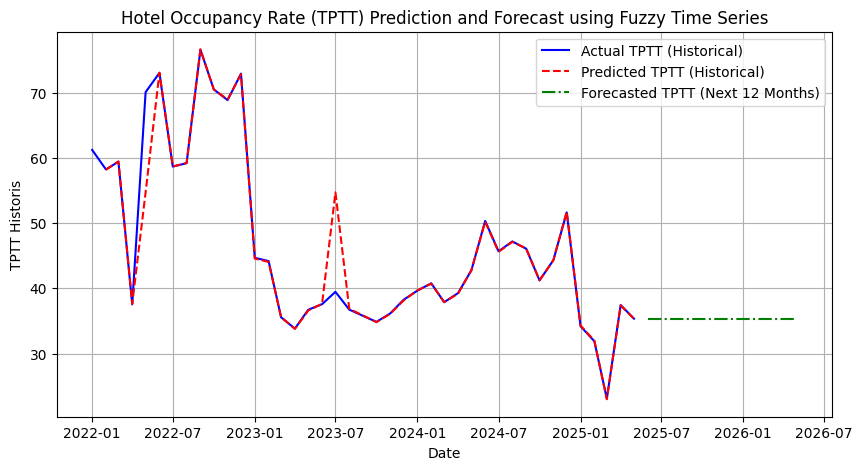

In [11]:
# Load the dataset
df = pd.read_csv('TPTT_Tanggal_Historis.csv')

# Convert 'Tanggal' to datetime and set as index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Select the 'TPTT Historis' column for prediction
data = df['TPTT Historis'].values

# Step 1: Define the Universe of Discourse (U)
D_min = data.min()
D_max = data.max()
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

# Step 2: Partition the Universe of Discourse into Intervals
num_intervals = 250 # Optimized Number of intervals
interval_length = (U_end - U_start) / num_intervals
intervals = []
for i in range(num_intervals):
    start = U_start + i * interval_length
    end = start + interval_length
    intervals.append((start, end))

# Step 3: Define Fuzzy Sets (A1, A2, ..., An)
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify the Historical Data
def fuzzify(value, intervals, num_intervals_arg):
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return num_intervals_arg - 1
    return None

fuzzified_data = [fuzzify(val, intervals, num_intervals) for val in data]

# Step 5 & 6: Establish Fuzzy Logical Relationships (FLRs) and Group FLRs (FLRGs)
flrs = {}
for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]
    next_state = fuzzified_data[i+1]
    if current_state not in flrs:
        flrs[current_state] = []
    flrs[current_state].append(next_state)

flrgs = {}
for current_state, next_states in flrs.items():
    flrgs[current_state] = sorted(list(set(next_states)))

# Step 7: Forecast (Defuzzification)
predictions = []
for i in range(len(fuzzified_data) - 1):
    current_fuzzy_state = fuzzified_data[i]
    if current_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            predictions.append(np.mean(predicted_midpoints))
        else:
            predictions.append(fuzzy_sets[current_fuzzy_state])
    else:
        predictions.append(fuzzy_sets[current_fuzzy_state])

actual_values = data[1:]
predicted_values = np.array(predictions)
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]

mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100
me = np.mean(actual_values_eval - predicted_values_eval)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Mean Error (ME): {me:.2f}")

# Forecast for the next 12 months
forecast_steps = 12
forecasted_values = []
last_actual_value = data[-1]
last_fuzzy_state = fuzzify(last_actual_value, intervals, num_intervals)
current_forecast_fuzzy_state = last_fuzzy_state

for _ in range(forecast_steps):
    if current_forecast_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_forecast_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            next_predicted_value = np.mean(predicted_midpoints)
        else:
            next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]
    else:
        next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]

    forecasted_values.append(next_predicted_value)
    current_forecast_fuzzy_state = fuzzify(next_predicted_value, intervals, num_intervals)

last_date = df.index[-1]
forecast_dates = pd.date_range(start=last_date, periods=forecast_steps + 1, freq='MS')[1:]

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['TPTT Historis'], label='Actual TPTT (Historical)', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted TPTT (Historical)', color='red', linestyle='--')
plt.plot(forecast_dates, forecasted_values, label='Forecasted TPTT (Next 12 Months)', color='green', linestyle='-.')
plt.title('Hotel Occupancy Rate (TPTT) Prediction and Forecast using Fuzzy Time Series')
plt.xlabel('Date')
plt.ylabel('TPTT Historis')
plt.legend()
plt.grid(True)
plt.savefig('tptt_prediction_and_forecast_fts.png')
print("Plot saved to tptt_prediction_and_forecast_fts.png")

forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecasted TPTT': forecasted_values})
print("\\nForecasted TPTT for the next 12 months:")
print(forecast_df.to_string(index=False))


## Membuat DataFrame untuk output CSV
# Menggabungkan data historis dan prediksi historis
historical_results_df = pd.DataFrame({
    'Tanggal': df.index[1:min_len+1], # Tanggal yang sesuai dengan prediksi historis
    'TPTT Historis': actual_values_eval,
    'TPTT Prediksi': predicted_values_eval
})

# Membuat DataFrame untuk data perkiraan
forecast_results_df = pd.DataFrame({
    'Tanggal': forecast_dates,
    'TPTT Historis': np.nan, # Tidak ada nilai historis untuk perkiraan
    'TPTT Prediksi': forecasted_values
})

# Menggabungkan kedua DataFrame
final_output_df = pd.concat([historical_results_df, forecast_results_df], ignore_index=True)

# Memastikan format tanggal sesuai
final_output_df['Tanggal'] = final_output_df['Tanggal'].dt.strftime('%Y-%m-%d')

# Menyimpan ke CSV
output_filename = 'tptt_hasil_prediksi.csv'
final_output_df.to_csv(output_filename, index=False)
print(f"\nHasil prediksi dan historis telah disimpan ke '{output_filename}' dalam format CSV.")
print("File ini dapat digunakan di Looker Studio.")